In [1]:
import zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix

warnings.filterwarnings("ignore")
%matplotlib inline

SEED = 42
TEST_SIZE = 0.30
ALPHA = 0.05
N_BOOT = 10_000
N_PERM = 10_000
N_SUBSAMPLES = 2_000
SUBSAMPLE_N = 500
N_SPLITS = 30
rng = np.random.default_rng(SEED)
print("Configuration ready.")

Configuration ready.


In [2]:
def load_data():
    return pd.read_csv("ai412020.csv")

raw = load_data()
print(raw.shape)
raw.head()

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
print(raw.dtypes, "\n")
print("Missing values:", int(raw.isna().sum().sum()))
counts = raw["Machine failure"].value_counts()
print(counts, f"\nFailure rate: {raw['Machine failure'].mean():.2%}")
raw.describe().T.round(2)

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object 

Missing values: 0
Machine failure
0    9661
1     339
Name: count, dtype: int64 
Failure rate: 3.39%


,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50,2886.90,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00,2.00,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.01,1.48,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.78,179.28,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.99,9.97,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95,63.65,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03,0.18,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00,0.07,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01,0.11,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.01,0.10,0.0,0.00,0.0,0.00,1.0


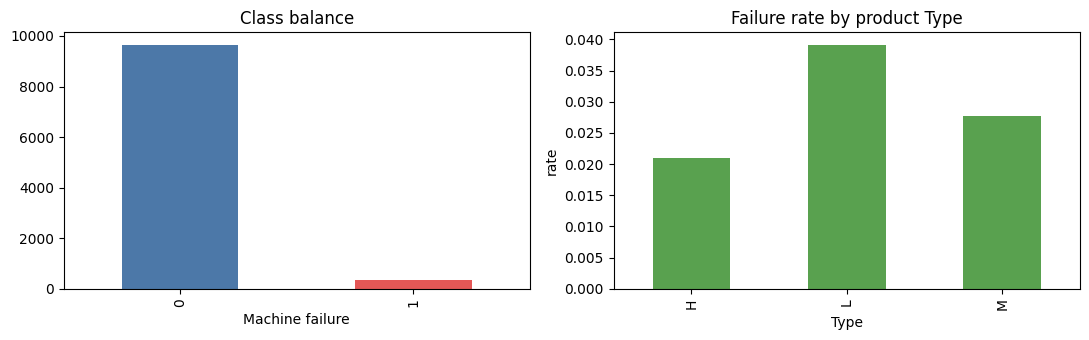

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
counts.plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"]); ax[0].set_title("Class balance")
raw.groupby("Type")["Machine failure"].mean().plot.bar(ax=ax[1], color="#59A14F")
ax[1].set_title("Failure rate by product Type"); ax[1].set_ylabel("rate")
plt.tight_layout(); plt.show()

In [5]:
TARGET = "Machine failure"
LEAK_COLS = ["TWF", "HDF", "PWF", "OSF", "RNF"]
ID_COLS = ["UDI", "Product ID"]

df = raw.drop(columns=ID_COLS + LEAK_COLS).rename(columns={
    "Air temperature [K]": "air_temp", "Process temperature [K]": "proc_temp",
    "Rotational speed [rpm]": "rpm", "Torque [Nm]": "torque", "Tool wear [min]": "tool_wear"})
df["Type"] = df["Type"].map({"L": 0, "M": 1, "H": 2})
X, y = df.drop(columns=TARGET), df[TARGET]
print("Features used:", list(X.columns))
df.head()

Features used: ['Type', 'air_temp', 'proc_temp', 'rpm', 'torque', 'tool_wear']


,Type,air_temp,proc_temp,rpm,torque,tool_wear,Machine failure
0,1,298.1,308.6,1551,42.8,0,0
1,0,298.2,308.7,1408,46.3,3,0
2,0,298.1,308.5,1498,49.4,5,0
3,0,298.2,308.6,1433,39.5,7,0
4,0,298.2,308.7,1408,40.0,9,0


In [6]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
y_te = yte.to_numpy()
n = len(y_te)
pd.DataFrame({"rows": [len(Xtr), n],
              "failures": [ytr.sum(), yte.sum()],
              "failure rate": [f"{ytr.mean():.2%}", f"{yte.mean():.2%}"]},
             index=["train", "test"])

,rows,failures,failure rate
train,7000,237,3.39%
test,3000,102,3.40%


In [7]:
def add_engineered(X):
    X = X.copy()
    X["temp_diff"] = X["proc_temp"] - X["air_temp"]
    X["power"] = X["torque"] * X["rpm"] * 2 * np.pi / 60
    X["strain"] = X["tool_wear"] * X["torque"]
    return X

def make_baseline():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

def make_improved(seed=SEED):
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=seed)

def fit_predict(Xtr, ytr, Xte, seed=SEED):
    base = make_baseline().fit(Xtr, ytr)
    imp = make_improved(seed).fit(add_engineered(Xtr), ytr)
    return base.predict(Xte), imp.predict(add_engineered(Xte))

pa, pb = fit_predict(Xtr, ytr, Xte)     # A = baseline, B = improved
print("Both models trained and predictions made on the SAME test set.")

Both models trained and predictions made on the SAME test set.


In [8]:
rows = []
for nm, p in [("Baseline (LogReg)", pa), ("Improved (RF + features)", pb)]:
    rows.append({"model": nm, "accuracy": accuracy_score(y_te, p),
                 "precision": precision_score(y_te, p, zero_division=0),
                 "recall": recall_score(y_te, p), "f1": f1_score(y_te, p)})
res = pd.DataFrame(rows).set_index("model").round(4)
print(f"Majority-class ('always no failure') accuracy = {1 - y_te.mean():.4f}  <- accuracy alone is misleading")
res

Majority-class ('always no failure') accuracy = 0.9660  <- accuracy alone is misleading


,accuracy,precision,recall,f1
model,,,,
Baseline (LogReg),0.9677,0.6087,0.1373,0.2240
Improved (RF + features),0.9940,0.9773,0.8431,0.9053


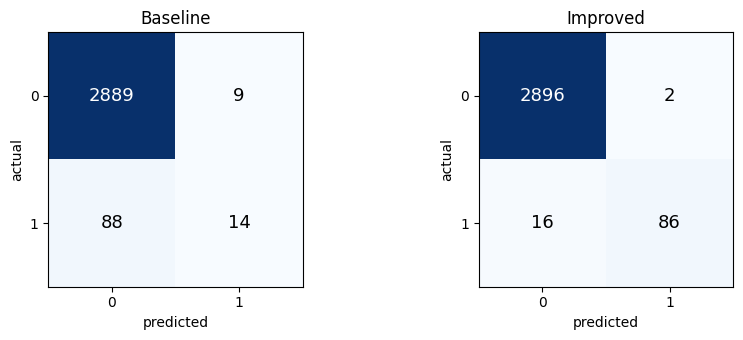

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
for a, (nm, p) in zip(ax, [("Baseline", pa), ("Improved", pb)]):
    cm = confusion_matrix(y_te, p)
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                   color="white" if cm[i, j] > cm.max()/2 else "black")
    a.set_title(nm); a.set_xticks([0, 1]); a.set_yticks([0, 1])
    a.set_xlabel("predicted"); a.set_ylabel("actual")
plt.tight_layout(); plt.show()

In [10]:
def wilson_ci(k, n, alpha=ALPHA):
    z = stats.norm.ppf(1 - alpha / 2)
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

ok_a, ok_b = (pa == y_te), (pb == y_te)
ka, kb = ok_a.sum(), ok_b.sum()
acc_a, acc_b = ka / n, kb / n
ci_a, ci_b = wilson_ci(ka, n), wilson_ci(kb, n)
pd.DataFrame({"accuracy": [acc_a, acc_b],
              "SE": [np.sqrt(acc_a*(1-acc_a)/n), np.sqrt(acc_b*(1-acc_b)/n)],
              "CI low": [ci_a[0], ci_b[0]], "CI high": [ci_a[1], ci_b[1]]},
             index=["Baseline", "Improved"]).round(4)

,accuracy,SE,CI low,CI high
Baseline,0.9677,0.0032,0.9607,0.9734
Improved,0.9940,0.0014,0.9905,0.9962


In [11]:
sub_diffs = np.empty(N_SUBSAMPLES)
for i in range(N_SUBSAMPLES):
    idx = rng.choice(n, SUBSAMPLE_N, replace=False)
    sub_diffs[i] = ok_b[idx].mean() - ok_a[idx].mean()

print(f"mean difference      : {sub_diffs.mean():+.4f}")
print(f"empirical SE (SD)    : {sub_diffs.std(ddof=1):.4f}")
print(f"improved better in   : {np.mean(sub_diffs > 0):.1%} of samples")
print(f"tied / worse         : {np.mean(sub_diffs == 0):.1%} / {np.mean(sub_diffs < 0):.1%}")
sw = stats.shapiro(sub_diffs[:500])
print(f"Shapiro-Wilk p = {sw.pvalue:.3f} (differences are discrete, so exact normality is not expected)")

mean difference      : +0.0264
empirical SE (SD)    : 0.0067
improved better in   : 100.0% of samples
tied / worse         : 0.0% / 0.0%
Shapiro-Wilk p = 0.000 (differences are discrete, so exact normality is not expected)


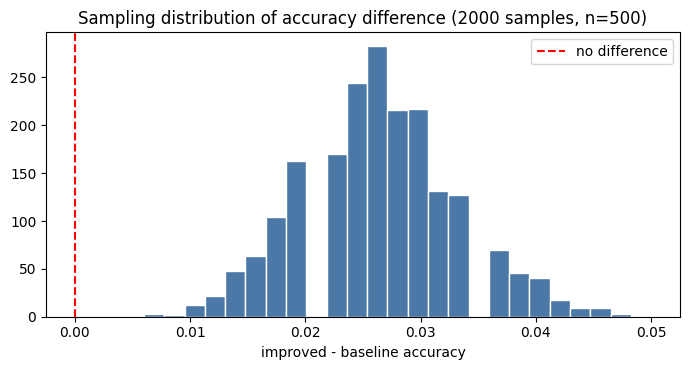

In [12]:
plt.figure(figsize=(7, 3.8))
plt.hist(sub_diffs, bins=25, color="#4C78A8", edgecolor="white")
plt.axvline(0, color="red", ls="--", label="no difference")
plt.title(f"Sampling distribution of accuracy difference ({N_SUBSAMPLES} samples, n={SUBSAMPLE_N})")
plt.xlabel("improved - baseline accuracy"); plt.legend(); plt.tight_layout(); plt.show()

In [13]:
d = ok_b.astype(int) - ok_a.astype(int)
d_bar, s_d = d.mean(), d.std(ddof=1)
se = s_d / np.sqrt(n)
zc = stats.norm.ppf(1 - ALPHA / 2)
print(f"Observed accuracy difference = {d_bar:+.4f}")
print(f"Normal-approx 95% CI         = [{d_bar - zc*se:+.4f}, {d_bar + zc*se:+.4f}]  (SE={se:.5f})")

Observed accuracy difference = +0.0263
Normal-approx 95% CI         = [+0.0205, +0.0322]  (SE=0.00300)


In [14]:
METRICS = {"accuracy": accuracy_score,
           "f1": lambda y, p: f1_score(y, p, zero_division=0),
           "recall": lambda y, p: recall_score(y, p, zero_division=0)}

def paired_bootstrap(y, pa, pb, name, n_boot=N_BOOT):
    f, m = METRICS[name], len(y)
    out = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, m, m)
        out[i] = f(y[idx], pb[idx]) - f(y[idx], pa[idx])
    return out

def boot_ci(s, alpha=ALPHA):
    return tuple(np.percentile(s, [100*alpha/2, 100*(1-alpha/2)]))

boots = {nm: paired_bootstrap(y_te, pa, pb, nm) for nm in ["accuracy", "f1", "recall"]}
obs = {nm: METRICS[nm](y_te, pb) - METRICS[nm](y_te, pa) for nm in boots}
pd.DataFrame({"observed diff": obs,
              "CI low": {k: boot_ci(v)[0] for k, v in boots.items()},
              "CI high": {k: boot_ci(v)[1] for k, v in boots.items()}}).round(4)

,observed diff,CI low,CI high
accuracy,0.0263,0.0207,0.0323
f1,0.6813,0.5786,0.7822
recall,0.7059,0.6147,0.7921


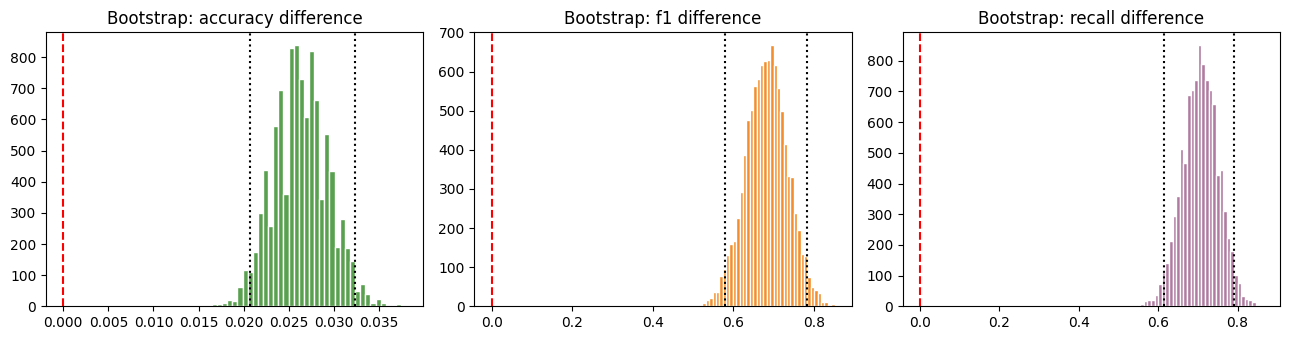

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for a, (nm, v), col in zip(ax, boots.items(), ["#59A14F", "#F28E2B", "#B07AA1"]):
    a.hist(v, bins=40, color=col, edgecolor="white")
    a.axvline(0, color="red", ls="--")
    for q in boot_ci(v): a.axvline(q, color="black", ls=":")
    a.set_title(f"Bootstrap: {nm} difference")
plt.tight_layout(); plt.show()

In [16]:
b = int(np.sum(ok_a & ~ok_b))     # baseline right, improved wrong
c = int(np.sum(~ok_a & ok_b))     # baseline wrong, improved right
tbl = pd.DataFrame([[int(np.sum(ok_a & ok_b)), b], [c, int(np.sum(~ok_a & ~ok_b))]],
                   index=["Improved correct", "Improved wrong"],
                   columns=["Baseline correct", "Baseline wrong"])
print(f"Discordant pairs: baseline-only correct b = {b}, improved-only correct c = {c}")
tbl

Discordant pairs: baseline-only correct b = 2, improved-only correct c = 81


,Baseline correct,Baseline wrong
Improved correct,2901,2
Improved wrong,81,16


In [17]:
mc = stats.binomtest(c, b + c, 0.5)
chi2 = (abs(b - c) - 1) ** 2 / (b + c)
print(f"Exact McNemar p-value        : {mc.pvalue:.3e}")
print(f"McNemar chi2 (cont. corr.)   : {chi2:.2f}, p = {stats.chi2.sf(chi2, 1):.3e}")

Exact McNemar p-value        : 7.211e-22
McNemar chi2 (cont. corr.)   : 73.30, p = 1.113e-17


In [18]:
t_stat = d_bar / se
p_t = 2 * stats.t.sf(abs(t_stat), n - 1)
print(f"t = {t_stat:.2f}, df = {n-1}, p = {p_t:.3e}")

t = 8.78, df = 2999, p = 2.679e-18


In [19]:
def paired_permutation(y, pa, pb, name, n_perm=N_PERM):
    f = METRICS[name]
    obs = f(y, pb) - f(y, pa)
    count = 0
    for _ in range(n_perm):
        swap = rng.random(len(y)) < 0.5
        a_, b_ = np.where(swap, pb, pa), np.where(swap, pa, pb)
        if abs(f(y, b_) - f(y, a_)) >= abs(obs) - 1e-12:
            count += 1
    return obs, (count + 1) / (n_perm + 1)

for nm in ["accuracy", "f1"]:
    o, p = paired_permutation(y_te, pa, pb, nm)
    print(f"{nm:8s}: observed diff = {o:+.4f}, permutation p = {p:.4f}  (minimum possible = {1/(N_PERM+1):.4f})")

accuracy: observed diff = +0.0263, permutation p = 0.0001  (minimum possible = 0.0001)
f1      : observed diff = +0.6813, permutation p = 0.0001  (minimum possible = 0.0001)


In [20]:
h = 2 * (np.arcsin(np.sqrt(acc_b)) - np.arcsin(np.sqrt(acc_a)))
print(f"Cohen's h = {h:.3f}  (0.2 small, 0.5 medium, 0.8 large)")
print(f"Improved model catches {obs['recall']*100:+.1f} percentage points more real failures (recall).")

Cohen's h = 0.207  (0.2 small, 0.5 medium, 0.8 large)
Improved model catches +70.6 percentage points more real failures (recall).


In [21]:
acc_diffs, f1_diffs = [], []
for s in range(N_SPLITS):
    a, bb, ya, yb = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=1000 + s)
    p1, p2 = fit_predict(a, ya, bb, seed=s)
    acc_diffs.append(accuracy_score(yb, p2) - accuracy_score(yb, p1))
    f1_diffs.append(f1_score(yb, p2) - f1_score(yb, p1))
acc_diffs, f1_diffs = np.array(acc_diffs), np.array(f1_diffs)

rows = []
for nm, v in [("accuracy", acc_diffs), ("F1", f1_diffs)]:
    t = stats.ttest_1samp(v, 0.0)
    ci = stats.t.interval(1 - ALPHA, len(v) - 1, loc=v.mean(), scale=stats.sem(v))
    rows.append({"metric": nm, "mean diff": v.mean(), "CI low": ci[0], "CI high": ci[1],
                 "t": t.statistic, "p": t.pvalue, "% splits improved better": np.mean(v > 0) * 100})
pd.DataFrame(rows).set_index("metric").round(4)

,mean diff,CI low,CI high,t,p,% splits improved better
metric,,,,,,
accuracy,0.0222,0.0214,0.0230,58.2734,0.0,100.0
F1,0.5873,0.5642,0.6103,52.0883,0.0,100.0


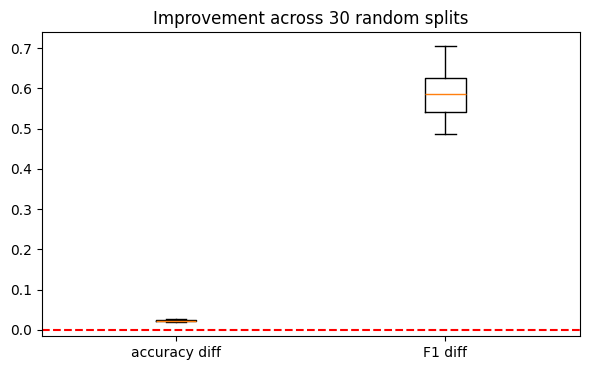

In [22]:
plt.figure(figsize=(6, 3.8))
plt.boxplot([acc_diffs, f1_diffs], labels=["accuracy diff", "F1 diff"])
plt.axhline(0, color="red", ls="--"); plt.title(f"Improvement across {N_SPLITS} random splits")
plt.tight_layout(); plt.show()

In [23]:
sig = mc.pvalue < ALPHA
ci_acc = (d_bar - zc*se, d_bar + zc*se)
ci_f1 = boot_ci(boots["f1"])
print(f"McNemar p = {mc.pvalue:.2e}  ->  {'REJECT' if sig else 'FAIL TO REJECT'} H0 at alpha = {ALPHA}")
print(f"Accuracy gain {d_bar:+.4f}  (95% CI {ci_acc[0]:+.4f} to {ci_acc[1]:+.4f})")
print(f"F1 gain       {obs['f1']:+.4f}  (95% CI {ci_f1[0]:+.4f} to {ci_f1[1]:+.4f})")
if sig and ci_acc[0] > 0 and ci_f1[0] > 0:
    print("\nDECISION: the improvement is statistically significant and NOT explained by test-sample variation.")
elif sig:
    print("\nDECISION: accuracy gain significant; evidence on the minority class is weaker - inspect F1 CI.")
else:
    print("\nDECISION: difference is consistent with sampling noise; cannot conclude the improved model is better.")

McNemar p = 7.21e-22  ->  REJECT H0 at alpha = 0.05
Accuracy gain +0.0263  (95% CI +0.0205 to +0.0322)
F1 gain       +0.6813  (95% CI +0.5786 to +0.7822)

DECISION: the improvement is statistically significant and NOT explained by test-sample variation.
